In [ ]:
Analyze the distribution of ratings and textual features in the Amazon Product Reviews dataset by visualizing review length, rating histograms, and word counts. Use this analysis to engineer features from the text data, then train a regression model to predict numerical ratings from review content, interpreting how text features influence ratings. [Kaggle Amazon Product Reviews]

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score


In [2]:
# 1. Load Dataset
# ================================

# Replace 'amazon_reviews.csv' with your dataset path
df = pd.read_csv("amazon.csv")

# Assume dataset has columns: ['reviewText', 'overall']
# where 'reviewText' = review content, 'overall' = rating (1-5)

print(df.head())
print(df.info())


   product_id                                       product_name  \
0  B07JW9H4J1  Wayona Nylon Braided USB to Lightning Fast Cha...   
1  B098NS6PVG  Ambrane Unbreakable 60W / 3A Fast Charging 1.5...   
2  B096MSW6CT  Sounce Fast Phone Charging Cable & Data Sync U...   
3  B08HDJ86NZ  boAt Deuce USB 300 2 in 1 Type-C & Micro USB S...   
4  B08CF3B7N1  Portronics Konnect L 1.2M Fast Charging 3A 8 P...   

                                            category discounted_price  \
0  Computers&Accessories|Accessories&Peripherals|...             ₹399   
1  Computers&Accessories|Accessories&Peripherals|...             ₹199   
2  Computers&Accessories|Accessories&Peripherals|...             ₹199   
3  Computers&Accessories|Accessories&Peripherals|...             ₹329   
4  Computers&Accessories|Accessories&Peripherals|...             ₹154   

  actual_price discount_percentage rating rating_count  \
0       ₹1,099                 64%    4.2       24,269   
1         ₹349                 43%  

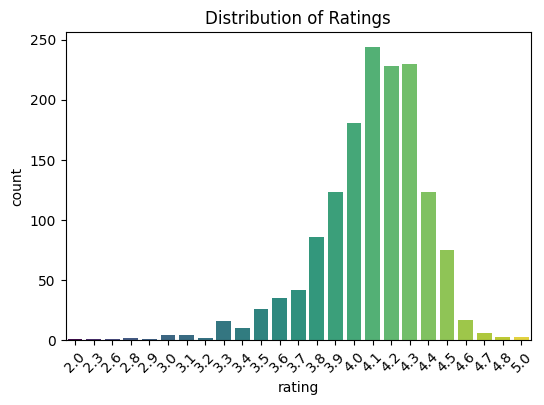

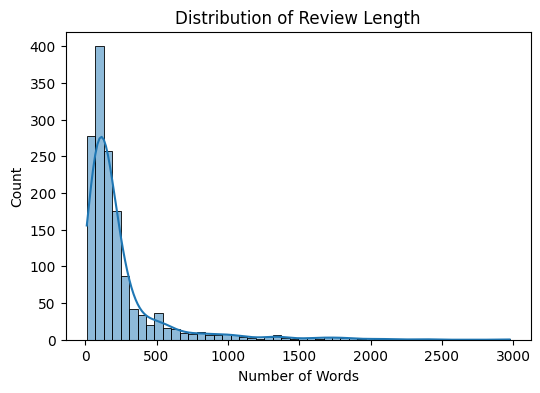

Average review length: 240.65437158469945
Max review length: 2974


In [25]:
#2. Exploratory Analysis
# ================================

# Review length (in words)
df['review_length'] = df['review_content'].astype(str).apply(lambda x: len(x.split()))

# Histogram of ratings
# Convert 'rating' to numeric, coercing errors to NaN
df['rating'] = pd.to_numeric(df['rating'])

plt.figure(figsize=(6,4))
sns.countplot(x='rating', data=df, hue='rating', palette='viridis', legend=False)
plt.title("Distribution of Ratings")
plt.xticks(rotation=45)
plt.show()

# Distribution of review length
plt.figure(figsize=(6,4))
sns.histplot(df['review_length'], bins=50, kde=True)
plt.title("Distribution of Review Length")
plt.xlabel("Number of Words")
plt.show()

# Word count statistics
print("Average review length:", df['review_length'].mean())
print("Max review length:", df['review_length'].max())

In [4]:
# Word count statistics
print("Average review length:", round(df['review_length'].mean(), 2))
print("Max review length:", df['review_length'].max())


Average review length: 240.77
Max review length: 2974


In [5]:
# 3. Feature Engineering (Text → TF-IDF)
# ================================

vectorizer = TfidfVectorizer(max_features=5000, stop_words='english')
X = vectorizer.fit_transform(df['review_content'].astype(str))

y = df['rating']

In [6]:
# 4. Train-Test Split
# ================================

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [26]:
# 5. Regression Models
# ================================

# Drop rows with NaN values in the 'rating' column
#df.dropna(subset=['rating'], inplace=True)

# Re-create X and y after dropping rows
#X = vectorizer.fit_transform(df['review_content'].astype(str))
#y = df['rating']

# Re-split the data
#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [27]:
# Linear Regression
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

LinearRegression()

In [28]:
y_pred_lr = lin_reg.predict(X_test)

In [29]:
print("Linear Regression Results:")
print("MSE:", mean_squared_error(y_test, y_pred_lr))
print("R^2:", r2_score(y_test, y_pred_lr))

Linear Regression Results:
MSE: 0.08772710383322946
R^2: -0.13055523419052473
----------------------------------------


In [20]:


# Random Forest Regressor
rf = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print("Random Forest Results:")
print("MSE:", mean_squared_error(y_test, y_pred_rf))
print("R^2:", r2_score(y_test, y_pred_rf))

Random Forest Results:
MSE: 0.06035010238907853
R^2: 0.22225719123691345


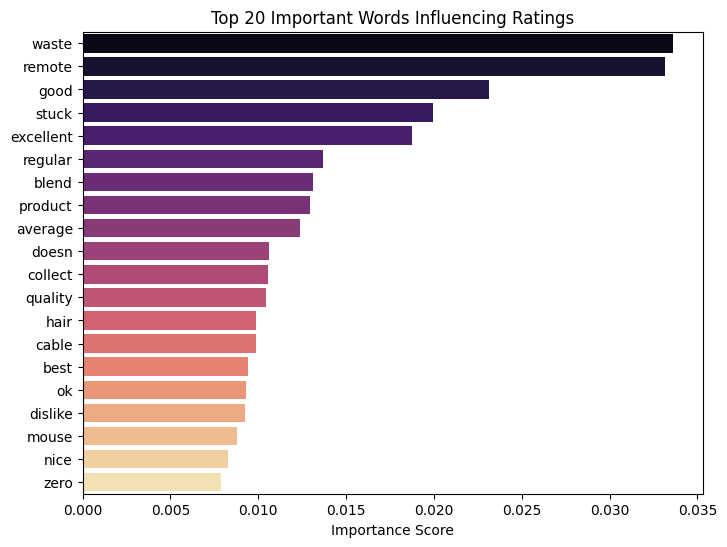

In [21]:
# 6. Interpret Feature Importance
# ================================

# For Random Forest
importances = rf.feature_importances_
indices = np.argsort(importances)[::-1][:20]  # top 20

top_features = [vectorizer.get_feature_names_out()[i] for i in indices]

plt.figure(figsize=(8,6))
sns.barplot(x=importances[indices], y=top_features, hue=top_features, palette="magma", legend=False)
plt.title("Top 20 Important Words Influencing Ratings")
plt.xlabel("Importance Score")
plt.show()
